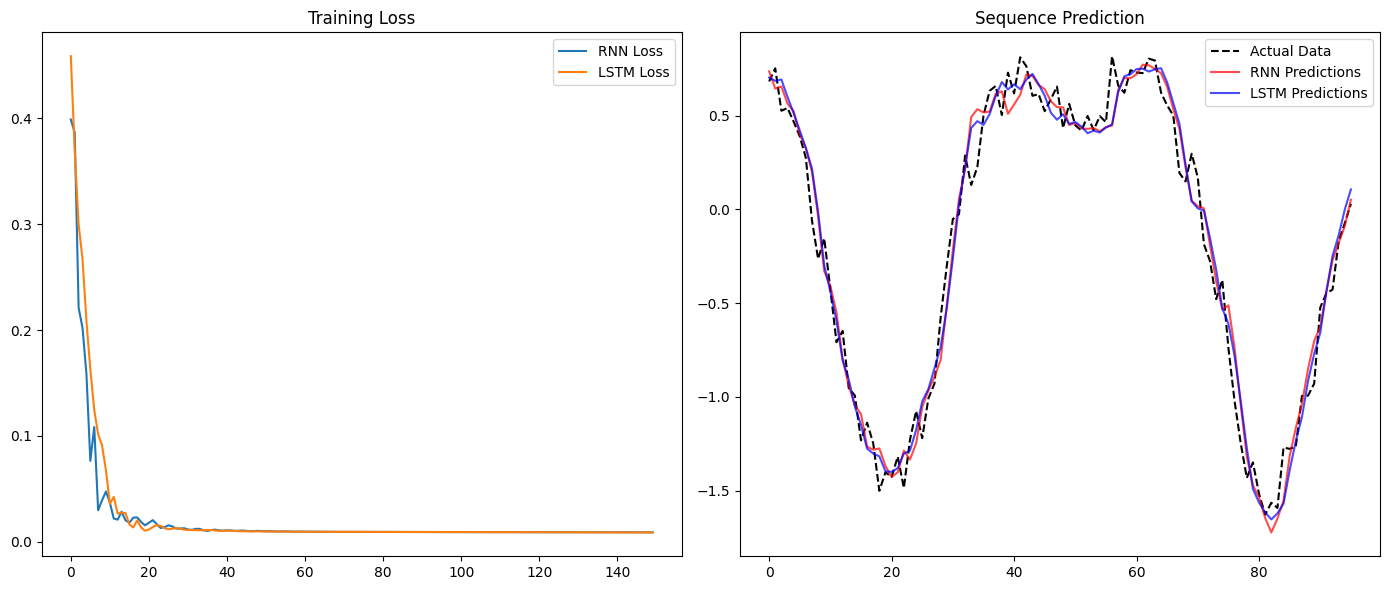

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

torch.manual_seed(42)
np.random.seed(42)

def generate_data():
    t = np.linspace(0, 50, 500)
    data = np.sin(t) + 0.5 * np.cos(2 * t) + np.random.normal(0, 0.1, 500)
    return data.reshape(-1, 1)

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

data = generate_data()
scaler = MinMaxScaler(feature_range=(-1, 1))
data_normalized = scaler.fit_transform(data)

seq_length = 20
X, y = create_sequences(data_normalized, seq_length)

train_size = int(len(X) * 0.8)
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

class SimpleRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1):
        super(SimpleRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.rnn(x, h0)
        out = self.fc(out[:, -1, :])
        return out

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, output_size=1):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :])
        return out

def train_model(model, X_train, y_train, epochs=100, lr=0.01):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    return history

rnn_model = SimpleRNN()
lstm_model = LSTMModel()

rnn_history = train_model(rnn_model, X_train, y_train, epochs=150)
lstm_history = train_model(lstm_model, X_train, y_train, epochs=150)

rnn_model.eval()
lstm_model.eval()
with torch.no_grad():
    rnn_preds = rnn_model(X_test).numpy()
    lstm_preds = lstm_model(X_test).numpy()

rnn_preds_inv = scaler.inverse_transform(rnn_preds)
lstm_preds_inv = scaler.inverse_transform(lstm_preds)
y_test_inv = scaler.inverse_transform(y_test.numpy())

def plot_results():
    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.plot(rnn_history, label='RNN Loss')
    plt.plot(lstm_history, label='LSTM Loss')
    plt.title('Training Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    time_axis = np.arange(len(y_test_inv))
    plt.plot(time_axis, y_test_inv, label='Actual Data', color='black', linestyle='dashed')
    plt.plot(time_axis, rnn_preds_inv, label='RNN Predictions', color='red', alpha=0.7)
    plt.plot(time_axis, lstm_preds_inv, label='LSTM Predictions', color='blue', alpha=0.7)
    plt.title('Sequence Prediction')
    plt.legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_results()